Mengimpor library yang diperlukan untuk manipulasi data (pandas, numpy), visualisasi (seaborn, matplotlib), serta pra-pemrosesan data (MultiLabelBinarizer, StandardScaler).

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler

Membaca file dataset "pokemon.csv" dan memuatnya ke dalam DataFrame pandas.

In [2]:
df = pd.read_csv("pokemon.csv")

Menampilkan ringkasan informasi dataset meliputi tipe data, jumlah entri, dan nilai non-null pada setiap kolom.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1007 entries, 0 to 1006
Data columns (total 24 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   pokemon_id                    1007 non-null   int64  
 1   pokemon_name                  1007 non-null   str    
 2   base_attack                   1007 non-null   int64  
 3   base_defense                  1007 non-null   int64  
 4   base_stamina                  1007 non-null   int64  
 5   type                          1007 non-null   str    
 6   rarity                        1007 non-null   str    
 7   charged_moves                 1007 non-null   str    
 8   fast_moves                    1007 non-null   str    
 9   candy_required                471 non-null    float64
 10  distance                      1007 non-null   int64  
 11  max_cp                        1007 non-null   int64  
 12  attack_probability            904 non-null    float64
 13  base_capture_r

Menampilkan 5 baris pertama dataset untuk melihat sampel isi data pada setiap fitur.

In [4]:
df.head()

,pokemon_id,pokemon_name,base_attack,base_defense,base_stamina,type,rarity,charged_moves,fast_moves,candy_required,...,base_flee_rate,dodge_probability,max_pokemon_action_frequency,min_pokemon_action_frequency,found_egg,found_evolution,found_wild,found_research,found_raid,found_photobomb
0,1,Bulbasaur,118,111,128,"['Grass', 'Poison']",Standard,"['Sludge Bomb', 'Seed Bomb', 'Power Whip']","['Vine Whip', 'Tackle']",NaN,...,-1.0,0.15,1.6,0.2,True,False,True,True,True,True
1,2,Ivysaur,151,143,155,"['Grass', 'Poison']",Standard,"['Sludge Bomb', 'Solar Beam', 'Power Whip']","['Razor Leaf', 'Vine Whip']",25.0,...,-1.0,0.15,1.6,0.2,False,True,True,True,True,True
2,3,Venusaur,198,189,190,"['Grass', 'Poison']",Standard,"['Sludge Bomb', 'Petal Blizzard', 'Solar Beam']","['Razor Leaf', 'Vine Whip']",100.0,...,-1.0,0.15,1.6,0.2,False,True,True,True,True,True
3,4,Charmander,116,93,118,['Fire'],Standard,"['Flame Charge', 'Flame Burst', 'Flamethrower']","['Ember', 'Scratch']",NaN,...,-1.0,0.15,1.6,0.2,True,False,True,True,True,True
4,5,Charmeleon,158,126,151,['Fire'],Standard,"['Fire Punch', 'Flame Burst', 'Flamethrower']","['Ember', 'Fire Fang']",25.0,...,-1.0,0.15,1.6,0.2,False,True,True,True,True,True


Memisahkan kolom target "max_cp" ke dalam variabel y serta menghapus kolom-kolom yang tidak digunakan dalam pemodelan.

In [5]:
y = df.pop("max_cp")

df2 = df.drop(columns=["pokemon_id","base_capture_rate", "base_flee_rate","charged_moves", "fast_moves", "attack_probability", "dodge_probability","max_pokemon_action_frequency", "min_pokemon_action_frequency","found_egg", "found_evolution", "found_wild","found_research", "found_raid", "found_photobomb"])

Menampilkan 5 baris pertama DataFrame df2 untuk memverifikasi fitur yang tersisa setelah penghapusan kolom.

In [6]:
df2.head()

,pokemon_name,base_attack,base_defense,base_stamina,type,rarity,candy_required,distance
0,Bulbasaur,118,111,128,"['Grass', 'Poison']",Standard,NaN,3
1,Ivysaur,151,143,155,"['Grass', 'Poison']",Standard,25.0,3
2,Venusaur,198,189,190,"['Grass', 'Poison']",Standard,100.0,3
3,Charmander,116,93,118,['Fire'],Standard,NaN,3
4,Charmeleon,158,126,151,['Fire'],Standard,25.0,3


Menampilkan 5 nilai pertama dari variabel target y (max_cp).

In [7]:
y.head()

0    1275
1    1943
2    3112
3    1121
4    1891
Name: max_cp, dtype: int64

Mengubah kolom nama Pokémon menjadi format numerik menggunakan LabelEncoder.

In [8]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df2["pokemon_name_enc"] = le.fit_transform(df2["pokemon_name"])
df2[["pokemon_name", "pokemon_name_enc"]].head()

,pokemon_name,pokemon_name_enc
0,Bulbasaur,92
1,Ivysaur,422
2,Venusaur,939
3,Charmander,122
4,Charmeleon,123


Memeriksa 5 baris pertama df2 setelah penambahan kolom hasil encoding nama Pokémon.

In [9]:
df2.head()

,pokemon_name,base_attack,base_defense,base_stamina,type,rarity,candy_required,distance,pokemon_name_enc
0,Bulbasaur,118,111,128,"['Grass', 'Poison']",Standard,NaN,3,92
1,Ivysaur,151,143,155,"['Grass', 'Poison']",Standard,25.0,3,422
2,Venusaur,198,189,190,"['Grass', 'Poison']",Standard,100.0,3,939
3,Charmander,116,93,118,['Fire'],Standard,NaN,3,122
4,Charmeleon,158,126,151,['Fire'],Standard,25.0,3,123


Menghapus kolom teks asli "pokemon_name" karena sudah digantikan oleh representasi numerik.

In [10]:
df2.drop(columns=["pokemon_name"], inplace=True)

Memeriksa jumlah nilai yang hilang (missing values / NaN) pada setiap kolom DataFrame.

In [11]:
df2.isnull().sum()

base_attack           0
base_defense          0
base_stamina          0
type                  0
rarity                0
candy_required      536
distance              0
pokemon_name_enc      0
dtype: int64

Mengisi missing values pada kolom "candy_required" dengan nilai 0 untuk Pokémon yang tidak memerlukan candy.

In [12]:
df2["candy_required"] = df2["candy_required"].fillna(0)

Memeriksa kembali untuk memastikan tidak ada lagi missing values di seluruh kolom.

In [13]:
df2.isnull().sum()

base_attack         0
base_defense        0
base_stamina        0
type                0
rarity              0
candy_required      0
distance            0
pokemon_name_enc    0
dtype: int64

Menghitung jumlah baris data duplikat dalam DataFrame.

In [14]:
df2.duplicated().sum()

np.int64(0)

Membersihkan format teks kolom "type" dan mengubahnya menjadi representasi biner multi-label menggunakan MultiLabelBinarizer.

In [15]:
df2["type"] = df2["type"].str.strip("[]").str.replace("'", "").str.split(", ")

mlb = MultiLabelBinarizer()
type_enc = pd.DataFrame(
    mlb.fit_transform(df2["type"]),
    columns=["type_" + t for t in mlb.classes_],
    index=df2.index,
)
type_enc.head()

,type_Bug,type_Dark,type_Dragon,type_Electric,type_Fairy,type_Fighting,type_Fire,type_Flying,type_Ghost,type_Grass,type_Ground,type_Ice,type_Normal,type_Poison,type_Psychic,type_Rock,type_Steel,type_Water
0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0


Melihat 5 baris teratas df2 sebelum menggabungkan kolom biner tipe Pokémon.

In [16]:
df2.head()

,base_attack,base_defense,base_stamina,type,rarity,candy_required,distance,pokemon_name_enc
0,118,111,128,"[Grass, Poison]",Standard,0.0,3,92
1,151,143,155,"[Grass, Poison]",Standard,25.0,3,422
2,198,189,190,"[Grass, Poison]",Standard,100.0,3,939
3,116,93,118,[Fire],Standard,0.0,3,122
4,158,126,151,[Fire],Standard,25.0,3,123


Menghapus kolom "type" asli dan menggabungkan kolom-kolom biner tipe Pokémon yang baru ke dalam DataFrame.

In [17]:
df2 = pd.concat([df2.drop(columns=["type"]), type_enc], axis=1)
df2.head()

,base_attack,base_defense,base_stamina,rarity,candy_required,distance,pokemon_name_enc,type_Bug,type_Dark,type_Dragon,...,type_Ghost,type_Grass,type_Ground,type_Ice,type_Normal,type_Poison,type_Psychic,type_Rock,type_Steel,type_Water
0,118,111,128,Standard,0.0,3,92,0,0,0,...,0,1,0,0,0,1,0,0,0,0
1,151,143,155,Standard,25.0,3,422,0,0,0,...,0,1,0,0,0,1,0,0,0,0
2,198,189,190,Standard,100.0,3,939,0,0,0,...,0,1,0,0,0,1,0,0,0,0
3,116,93,118,Standard,0.0,3,122,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,158,126,151,Standard,25.0,3,123,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Menerapkan one-hot encoding pada kolom "rarity" dan menghapus kolom "rarity_Standard" untuk menghindari dummy variable trap.

In [18]:
rarity_raw = df2["rarity"].copy()

df2 = pd.get_dummies(df2, columns=["rarity"], prefix="rarity", dtype=int)
df2 = df2.drop(columns=["rarity_Standard"])

Menampilkan statistik deskriptif dari seluruh fitur numerik dan kategorikal pada dataset.

In [19]:
df2.describe(include="all")

,base_attack,base_defense,base_stamina,candy_required,distance,pokemon_name_enc,type_Bug,type_Dark,type_Dragon,type_Electric,...,type_Ice,type_Normal,type_Poison,type_Psychic,type_Rock,type_Steel,type_Water,rarity_Legendary,rarity_Mythic,rarity_Ultra beast
count,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,...,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000
mean,166.268123,143.824230,171.078451,30.867925,5.058590,503.000000,0.093347,0.077458,0.064548,0.068520,...,0.053625,0.123138,0.079444,0.101291,0.075472,0.069513,0.150943,0.063555,0.021847,0.010924
std,59.382689,52.023124,47.956251,53.461302,5.458459,290.840162,0.291062,0.267449,0.245849,0.252762,...,0.225387,0.328759,0.270565,0.301864,0.264282,0.254452,0.358172,0.244080,0.146257,0.103995
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,119.000000,103.000000,137.000000,0.000000,3.000000,251.500000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,165.000000,142.000000,167.000000,0.000000,3.000000,503.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,211.000000,179.000000,193.000000,50.000000,5.000000,754.500000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,414.000000,505.000000,496.000000,400.000000,20.000000,1006.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Membuat visualisasi heatmap korelasi antar fitur dan target untuk mengamati hubungan linear antar variabel.

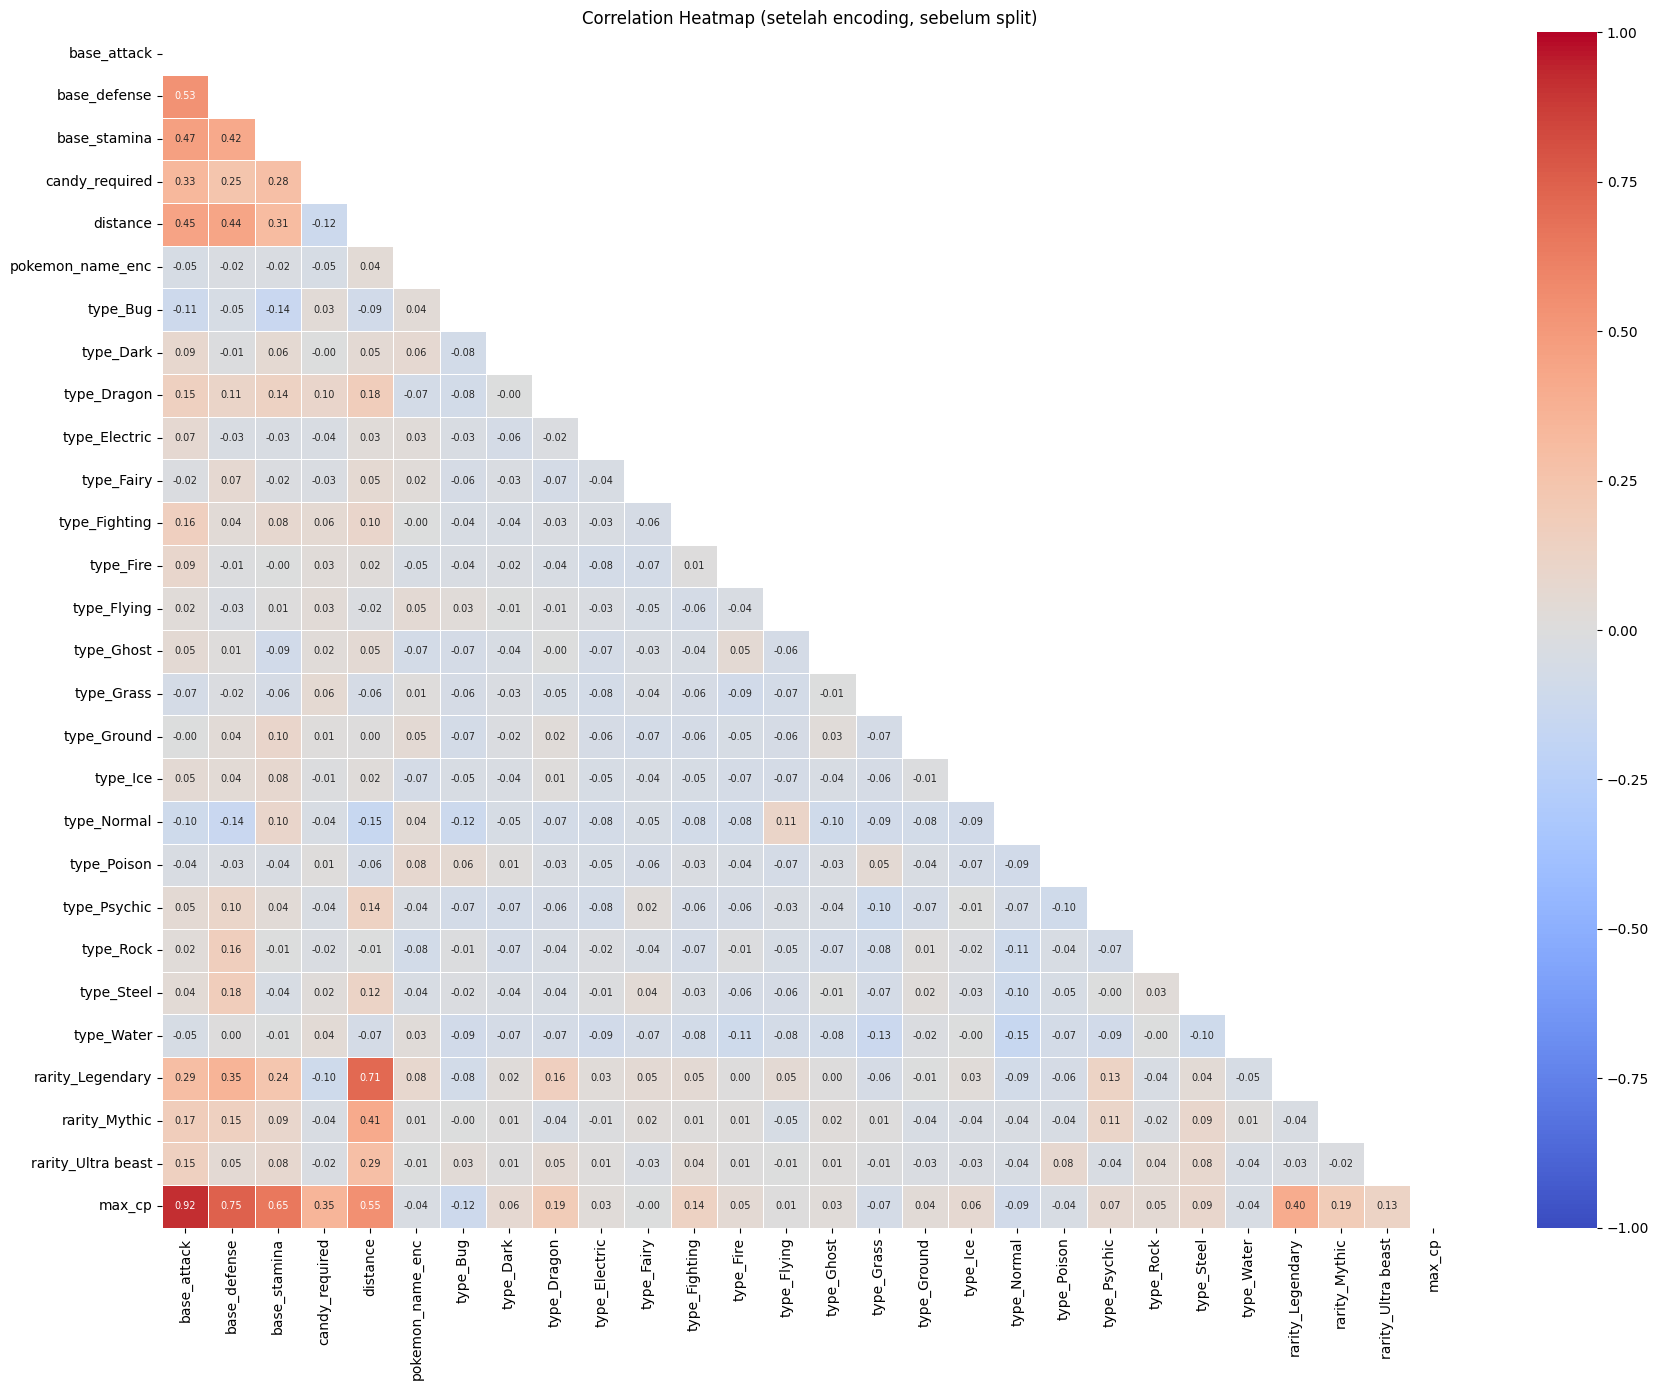

In [20]:
corr = pd.concat([df2, y], axis=1).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(18, 14))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 7},
            cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap (setelah encoding, sebelum split)")
plt.tight_layout()
plt.show()

Memeriksa kembali struktur dan tipe data seluruh kolom sebelum tahap deteksi anomali.

In [21]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 1007 entries, 0 to 1006
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   base_attack         1007 non-null   int64  
 1   base_defense        1007 non-null   int64  
 2   base_stamina        1007 non-null   int64  
 3   candy_required      1007 non-null   float64
 4   distance            1007 non-null   int64  
 5   pokemon_name_enc    1007 non-null   int64  
 6   type_Bug            1007 non-null   int64  
 7   type_Dark           1007 non-null   int64  
 8   type_Dragon         1007 non-null   int64  
 9   type_Electric       1007 non-null   int64  
 10  type_Fairy          1007 non-null   int64  
 11  type_Fighting       1007 non-null   int64  
 12  type_Fire           1007 non-null   int64  
 13  type_Flying         1007 non-null   int64  
 14  type_Ghost          1007 non-null   int64  
 15  type_Grass          1007 non-null   int64  
 16  type_Ground      

Mendeteksi baris data anomali di mana nilai statistik dasar (attack, defense, atau stamina) bernilai 0.

In [ ]:
stat_cols = ["base_attack", "base_defense", "base_stamina"]
anomali = (df2[stat_cols] == 0).any(axis=1)
pd.concat([df2[anomali], y[anomali]], axis=1)

,base_attack,base_defense,base_stamina,candy_required,distance,pokemon_name_enc,type_Bug,type_Dark,type_Dragon,type_Electric,...,type_Normal,type_Poison,type_Psychic,type_Rock,type_Steel,type_Water,rarity_Legendary,rarity_Mythic,rarity_Ultra beast,max_cp
678,0,0,0,0.0,5,396,0,0,0,0,...,0,0,0,0,1,0,0,0,0,16
679,0,0,0,25.0,5,212,0,0,0,0,...,0,0,0,0,1,0,0,0,0,16
680,0,0,0,100.0,5,4,0,0,0,0,...,0,0,0,0,1,0,0,0,0,16


Menyaring dan menghapus data anomali agar hanya menyisakan data dengan statistik dasar yang valid (> 0).

In [ ]:
valid = (df2[stat_cols] > 0).all(axis=1)
df2 = df2[valid]
y = y[valid]
print(df2.shape, y.shape)

(1004, 27) (1004,)


Membagi dataset menjadi data latih (80%) dan data uji (20%) menggunakan train_test_split.

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df2, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(803, 27) (201, 27) (803,) (201,)


Melihat ringkasan statistik fitur numerik pada data latih sebelum dilakukan standardisasi skala.

In [ ]:
num_cols = ["base_attack", "base_defense", "base_stamina", "candy_required", "distance"]
X_train[num_cols].describe().loc[["mean", "std", "min", "max"]]

,base_attack,base_defense,base_stamina,candy_required,distance
mean,165.919054,144.566625,171.108344,30.850560,5.139477
std,59.560817,52.928399,48.648410,56.312165,5.557496
min,17.000000,32.000000,1.000000,0.000000,1.000000
max,414.000000,505.000000,496.000000,400.000000,20.000000


Melakukan standardisasi skala fitur numerik menggunakan StandardScaler untuk menyamakan rentang nilai.

In [ ]:
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

X_train_scaled.head()

,base_attack,base_defense,base_stamina,candy_required,distance,pokemon_name_enc,type_Bug,type_Dark,type_Dragon,type_Electric,...,type_Ice,type_Normal,type_Poison,type_Psychic,type_Rock,type_Steel,type_Water,rarity_Legendary,rarity_Mythic,rarity_Ultra beast
78,-0.956242,-0.880352,0.738236,-0.548190,-0.385211,800,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
29,-0.821841,-0.464438,0.018340,-0.103960,-0.385211,591,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
280,-0.821841,-1.031594,-1.133494,-0.103960,-0.025113,444,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
507,0.673361,0.707686,0.553120,1.228732,-0.745310,841,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
652,-0.838641,-0.804732,-1.051220,-0.548190,-0.385211,275,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Memeriksa nilai mean dan standar deviasi pada data latih untuk memastikan fitur numerik berhasil distandardisasi.

In [ ]:
X_train_scaled[num_cols].describe().loc[["mean", "std"]].round(3)

,base_attack,base_defense,base_stamina,candy_required,distance
mean,0.000,-0.000,-0.000,0.000,0.000
std,1.001,1.001,1.001,1.001,1.001


Mengimpor berbagai model regresi dan metrik evaluasi (MAE, MSE, R2 Score) dari scikit-learn.

In [30]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Mendefinisikan fungsi evaluate untuk melatih model, melakukan prediksi, dan menghitung metrik evaluasi secara otomatis.

In [31]:
models = {}
results = {}
preds = {}

def evaluate(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    pred_train = model.predict(Xtr)
    pred_test = model.predict(Xte)

    models[name] = model
    preds[name] = pred_test
    results[name] = {
        "model": name,
        "MAE": mean_absolute_error(y_test, pred_test),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
        "R2_train": r2_score(y_train, pred_train),
        "R2_test": r2_score(y_test, pred_test),
    }
    return results[name]

Melatih dan mengevaluasi performa model Linear Regression pada data yang telah distandardisasi.

In [ ]:
evaluate("Linear Regression", LinearRegression(), X_train_scaled, X_test_scaled)

{'model': 'Linear Regression',
 'MAE': 99.95855467682071,
 'RMSE': np.float64(135.68401057561815),
 'R2_train': 0.9764613178319246,
 'R2_test': 0.9825227712850771}

Melatih dan mengevaluasi performa model Ridge Regression dengan regularisasi L2.

In [ ]:
evaluate("Ridge", Ridge(alpha=1.0), X_train_scaled, X_test_scaled)

{'model': 'Ridge',
 'MAE': 99.66181243401401,
 'RMSE': np.float64(135.23635857393694),
 'R2_train': 0.9764558727680668,
 'R2_test': 0.9826379036471999}

Melatih dan mengevaluasi performa model Lasso Regression dengan regularisasi L1.

In [ ]:
evaluate("Lasso", Lasso(alpha=1.0, max_iter=10000), X_train_scaled, X_test_scaled)

{'model': 'Lasso',
 'MAE': 97.90064251642144,
 'RMSE': np.float64(131.95606889065357),
 'R2_train': 0.9761741230449841,
 'R2_test': 0.9834699577552665}

Melatih dan mengevaluasi performa model K-Nearest Neighbors (KNN) Regressor dengan k=5.

In [ ]:
evaluate("KNN", KNeighborsRegressor(n_neighbors=5), X_train_scaled, X_test_scaled)

{'model': 'KNN',
 'MAE': 762.4995024875623,
 'RMSE': np.float64(948.2326378702581),
 'R2_train': 0.4956278446759175,
 'R2_test': 0.14641843972843904}

Melatih dan mengevaluasi performa model ensemble Random Forest Regressor menggunakan 300 decision tree.

In [ ]:
evaluate("Random Forest", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), X_train, X_test)

{'model': 'Random Forest',
 'MAE': 72.7785903814262,
 'RMSE': np.float64(133.16487360254197),
 'R2_train': 0.9949590665856899,
 'R2_test': 0.9831657183911536}

Melatih dan mengevaluasi performa model ensemble Gradient Boosting Regressor.

In [ ]:
evaluate("Gradient Boosting", GradientBoostingRegressor(random_state=42), X_train, X_test)

{'model': 'Gradient Boosting',
 'MAE': 75.45598940495678,
 'RMSE': np.float64(117.86264630806858),
 'R2_train': 0.99718475647989,
 'R2_test': 0.9868123442680168}

Merangkum seluruh hasil evaluasi model ke dalam DataFrame dan mengurutkannya berdasarkan nilai RMSE terendah.

In [38]:
df_results = pd.DataFrame(list(results.values())).sort_values("RMSE").reset_index(drop=True)
df_results.round(4)

,model,MAE,RMSE,R2_train,R2_test
0,Gradient Boosting,75.4560,117.8626,0.9972,0.9868
1,Lasso,97.9006,131.9561,0.9762,0.9835
2,Random Forest,72.7786,133.1649,0.9950,0.9832
3,Ridge,99.6618,135.2364,0.9765,0.9826
4,Linear Regression,99.9586,135.6840,0.9765,0.9825
5,KNN,762.4995,948.2326,0.4956,0.1464


Membuat diagram batang untuk membandingkan metrik error MAE dan RMSE dari setiap model pada data uji.

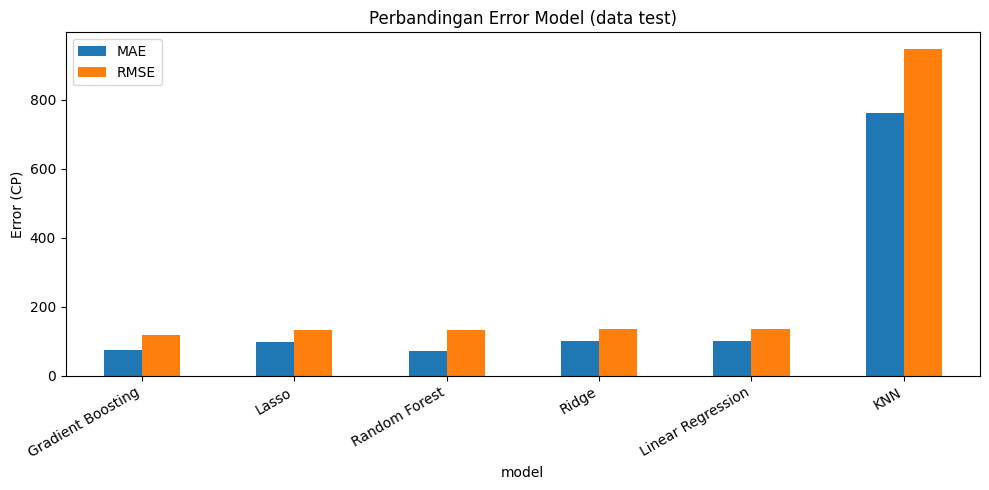

In [39]:
df_results.set_index("model")[["MAE", "RMSE"]].plot(kind="bar", figsize=(10, 5))
plt.title("Perbandingan Error Model (data test)")
plt.ylabel("Error (CP)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Menampilkan plot perbandingan nilai aktual vs prediksi serta plot residual untuk mengevaluasi kualitas model terbaik.

model terbaik: Gradient Boosting


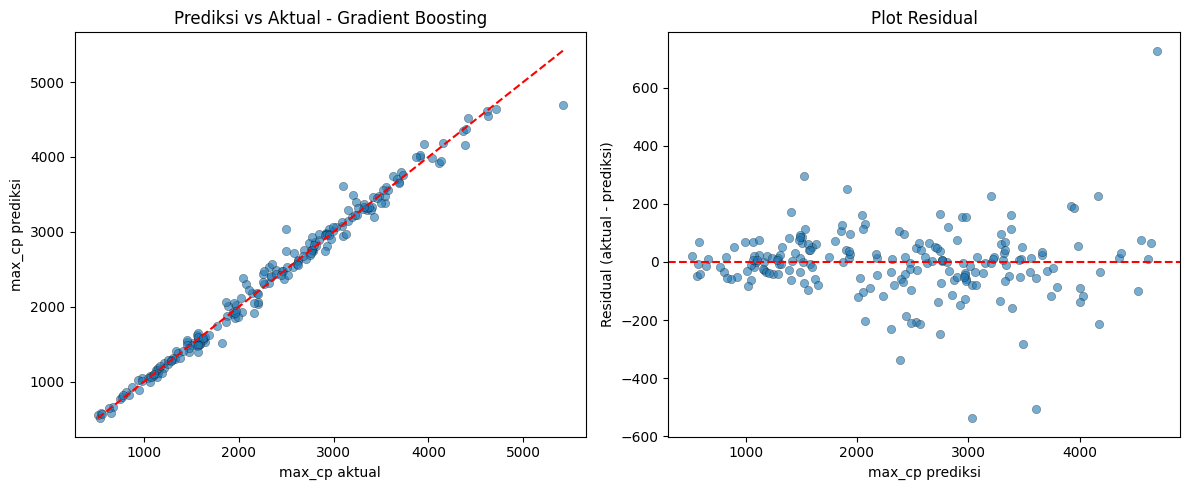

In [40]:
best_name = df_results.loc[0, "model"]
pred_best = preds[best_name]
resid = y_test - pred_best
print("model terbaik:", best_name)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, pred_best, alpha=0.6, edgecolor="k", linewidth=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("max_cp aktual")
plt.ylabel("max_cp prediksi")
plt.title(f"Prediksi vs Aktual - {best_name}")

plt.subplot(1, 2, 2)
plt.scatter(pred_best, resid, alpha=0.6, edgecolor="k", linewidth=0.3)
plt.axhline(0, color="r", linestyle="--")
plt.xlabel("max_cp prediksi")
plt.ylabel("Residual (aktual - prediksi)")
plt.title("Plot Residual")

plt.tight_layout()
plt.show()

Membuat grafik 10 fitur teratas yang paling berpengaruh terhadap prediksi Max CP berdasarkan model Random Forest.

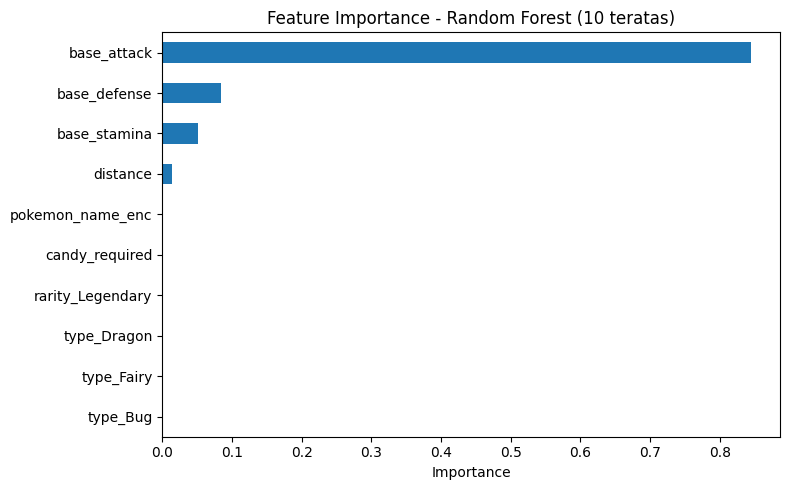

In [41]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=X_train.columns).sort_values()

plt.figure(figsize=(8, 5))
imp.tail(10).plot(kind="barh")
plt.title("Feature Importance - Random Forest (10 teratas)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()